# Combined SNOTEL + MSNT + CDEC station distribution in the Sierra Nevada box

Spatial and temporal coverage of the 312-station combined daily-SWE network built by
`build_combined_sierra_swe.py` -- the exact dataset
`CA_snowmelt_events_detrend_5day.ipynb` analyzes, read here from
`combined_sierra_stations.csv` and `combined_sierra_swe_wy1990-2026.csv`.

Three source networks fill the box: NRCS **SNOTEL** (`SNTL`, north of ~38.1N,
AWDB-QC'd), NRCS **MSNT** ("Cooperator Snow Sensors", south of ~38.1N --
Yosemite/Mammoth/Kings Canyon/Sequoia/Kern -- also AWDB-QC'd), and **CDEC** (same
southern terrain plus additional sites, heuristically QC'd by `qc_cdec_swe.py`). Of
the 312 in-box stations, only **147 report at daily ("D") resolution** and feed the
event-detection pipeline; the other 165 are CDEC manual snow-course ("M"-only) sites
with no automated sensor, metadata-only here and there.


In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path

# Pin PROJ_DATA before cartopy/pyproj's first import -- see the companion notebooks'
# setup cells for why (GDAL's bundled PROJ context doesn't reliably find its own
# proj.db otherwise, printing a harmless but noisy error to stderr).
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd
import xarray as xr


In [2]:
DATA_DIR = '/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/'

# Sierra Nevada bounding box, standard -180/180 longitude -- same bounds
# CA_snowmelt_events_detrend_5day.ipynb uses (combined_sierra_stations.csv already
# stores standard-convention lon/lat, unlike the raw per-network fetch scripts, which
# use ERA5's 0-360 convention)
SIERRA_LAT_S, SIERRA_LAT_N = 34.5, 40.0
SIERRA_LON_W, SIERRA_LON_E = -121.0, -116.5

stations = pd.read_csv(DATA_DIR + 'combined_sierra_stations.csv').rename(
    columns={'station_id': 'stationTriplet'})
sierra_mask = (
    stations.latitude.between(SIERRA_LAT_S, SIERRA_LAT_N) &
    stations.longitude.between(SIERRA_LON_W, SIERRA_LON_E)
)
stations = stations[sierra_mask].reset_index(drop=True)

swe = pd.read_csv(DATA_DIR + 'combined_sierra_swe_wy1990-2026.csv', parse_dates=['date']) \
        .rename(columns={'station_id': 'stationTriplet'})
swe = swe[swe.stationTriplet.isin(stations.stationTriplet)].copy()

# "daily" here matches CA_snowmelt_events_detrend_5day.ipynb's event-detection filter
# exactly: keep only stations with at least one duration="D" (automated daily sensor)
# reading. The rest are CDEC manual snow-course ("M") sites -- too infrequent for a
# backward-difference decline metric, so metadata-only there too.
daily_ids = set(swe[swe.duration == 'D'].stationTriplet)
stations['daily'] = stations['stationTriplet'].isin(daily_ids)

print(f'{len(stations)} combined SNOTEL+MSNT+CDEC stations in the Sierra box, by source:')
print(stations['source'].value_counts().to_dict())
print(f'\n{stations.daily.sum()} report at daily resolution (feed the event-detection '
      f'pipeline); {(~stations.daily).sum()} are manual-only (metadata-only there too), '
      f'by source:')
print(stations.groupby('source')['daily'].value_counts().unstack(fill_value=0)
      .reindex(columns=[True, False]).rename(columns={True: 'daily', False: 'manual-only'})
      .rename_axis(columns=None).to_string())
stations.sort_values('latitude', ascending=False).reset_index(drop=True)


312 combined SNOTEL+MSNT+CDEC stations in the Sierra box, by source:
{'CDEC': 209, 'MSNT': 67, 'SNTL': 36}

147 report at daily resolution (feed the event-detection pipeline); 165 are manual-only (metadata-only there too), by source:
        daily  manual-only
source                    
CDEC       44          165
MSNT       67            0
SNTL       36            0


,stationTriplet,name,latitude,longitude,elevation_ft,source,daily
0,ABY,ABBEY,39.954160,-120.540510,5650.0,CDEC,False
1,GRZ:CA:MSNT,Grizzly Ridge,39.917000,-120.645000,6890.0,MSNT,True
2,FCV,FRENCHMAN COVE,39.897000,-120.265000,5800.0,CDEC,False
3,PLP:CA:MSNT,Pilot Peak,39.786000,-120.875000,6780.0,MSNT,True
4,EUR,EUREKA LAKE,39.761650,-120.714717,6200.0,CDEC,False
...,...,...,...,...,...,...,...
307,BHM,BEACH MEADOWS,36.119583,-118.294133,7580.0,CDEC,False
308,BNM,BONITA MEADOWS,36.038000,-118.328000,8300.0,CDEC,False
309,PSC:CA:MSNT,Pascoes,35.967000,-118.350000,9610.0,MSNT,True
310,RMD,ROUND MEADOW,35.965000,-118.360000,9000.0,CDEC,False


## Spatial distribution

In [3]:
# terrain height from the ERA5 invariant surface geopotential, cropped to the
# Sierra box with a margin (same source as plot_ca_box_map.ipynb)
G = 9.80665  # m/s^2

flnm_invariant = (
    '/glade/campaign/collections/rda/data/d633000/e5.oper.invariant/197901/'
    'e5.oper.invariant.128_129_z.ll025sc.1979010100_1979010100.nc'
)

MAP_LAT_S, MAP_LAT_N = SIERRA_LAT_S - 1.5, SIERRA_LAT_N + 1.5
MAP_LON_W, MAP_LON_E = SIERRA_LON_W - 2.0, SIERRA_LON_E + 2.0

# ERA5 invariant longitude is in 0-360; convert the (-180/180) box to that convention
# for cropping, then shift the result back to -180/180 to match the stations below
MAP_LON_W_360, MAP_LON_E_360 = MAP_LON_W + 360.0, MAP_LON_E + 360.0
with xr.open_dataset(flnm_invariant) as ds:
    elevation = (ds['Z'].isel(time=0) / G).sel(
        latitude=slice(MAP_LAT_N, MAP_LAT_S),
        longitude=slice(MAP_LON_W_360, MAP_LON_E_360),
    ).load()
elevation = elevation.assign_coords(longitude=elevation['longitude'] - 360.0)
elevation = elevation.clip(min=0)


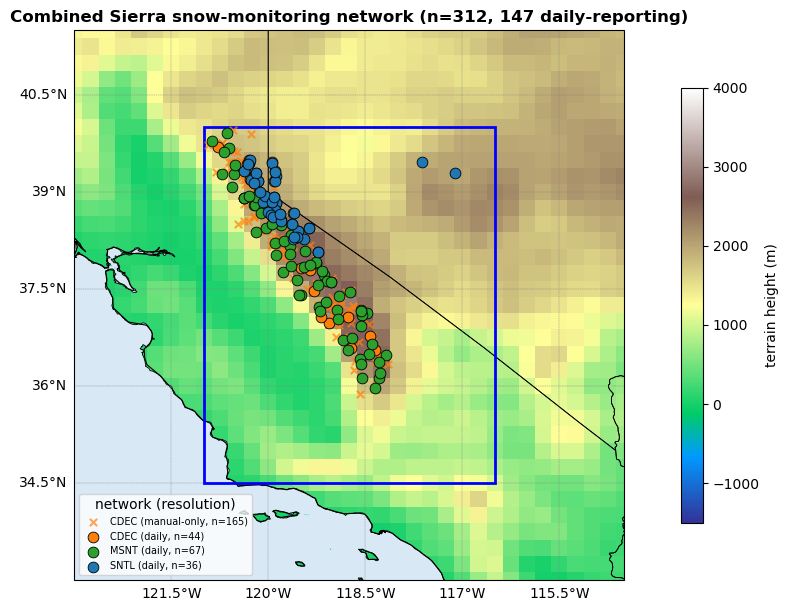

In [4]:
fig = plt.figure(figsize=(8, 9))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([MAP_LON_W, MAP_LON_E, MAP_LAT_S, MAP_LAT_N], crs=ccrs.PlateCarree())

terrain = ax.pcolormesh(
    elevation['longitude'], elevation['latitude'], elevation,
    cmap='terrain', vmin=-1500, vmax=4000,
    shading='auto', transform=ccrs.PlateCarree(), zorder=0,
)
cbar = plt.colorbar(terrain, ax=ax, orientation='vertical', shrink=0.5, pad=0.08)
cbar.set_label('terrain height (m)')

ax.add_feature(cfeature.OCEAN, facecolor='#d9e8f5', zorder=1)
ax.coastlines(resolution='50m', linewidth=0.8, zorder=2)
ax.add_feature(cfeature.STATES, linewidth=0.6, edgecolor='black', zorder=2)

box = mpatches.Rectangle(
    (SIERRA_LON_W, SIERRA_LAT_S), SIERRA_LON_E - SIERRA_LON_W, SIERRA_LAT_N - SIERRA_LAT_S,
    linewidth=2, edgecolor='blue', facecolor='none', zorder=3,
    transform=ccrs.PlateCarree(),
)
ax.add_patch(box)

source_colors = {'SNTL': 'tab:blue', 'MSNT': 'tab:green', 'CDEC': 'tab:orange'}
for (source, daily), grp in stations.groupby(['source', 'daily']):
    label = f"{source} ({'daily' if daily else 'manual-only'}, n={len(grp)})"
    scatter_kwargs = dict(edgecolor='black', linewidth=0.6) if daily else {}
    ax.scatter(
        grp['longitude'], grp['latitude'],
        s=60 if daily else 28, marker='o' if daily else 'x',
        color=source_colors[source], alpha=1.0 if daily else 0.7,
        transform=ccrs.PlateCarree(), zorder=5 if daily else 4, label=label,
        **scatter_kwargs,
    )

gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle='--', color='gray')
gl.top_labels = False
gl.right_labels = False

ax.legend(loc='lower left', fontsize=7, title='network (resolution)')
ax.set_title(f'Combined Sierra snow-monitoring network (n={len(stations)}, '
             f'{stations.daily.sum()} daily-reporting)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


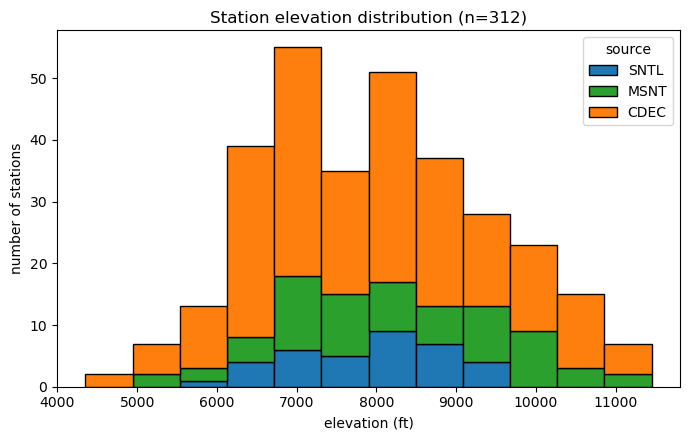

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
source_order = ['SNTL', 'MSNT', 'CDEC']
bins = np.linspace(stations['elevation_ft'].min(), stations['elevation_ft'].max(), 13)
ax.hist(
    [stations.loc[stations.source == s, 'elevation_ft'] for s in source_order],
    bins=bins, stacked=True, color=[source_colors[s] for s in source_order],
    edgecolor='black', label=source_order,
)
ax.set_xlabel('elevation (ft)')
ax.set_ylabel('number of stations')
ax.set_title(f'Station elevation distribution (n={len(stations)})')
ax.legend(title='source')
plt.tight_layout()
plt.show()


## Temporal distribution

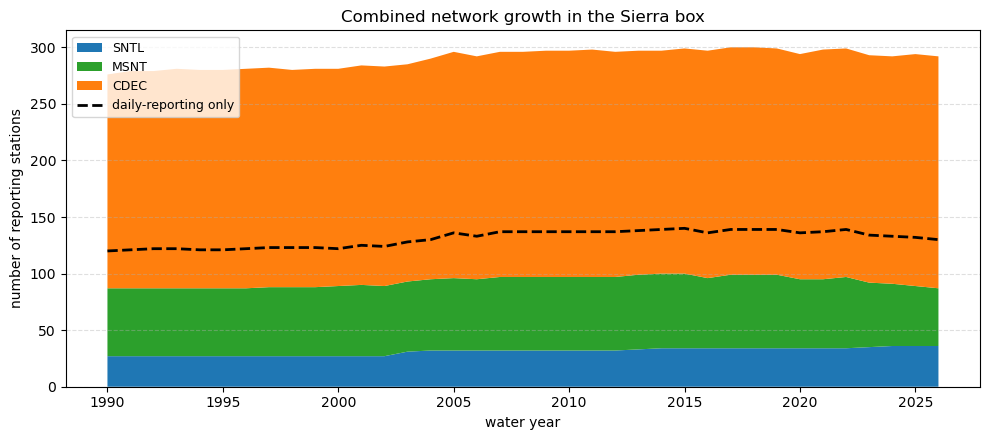

In [6]:
# network growth: number of stations with >=1 valid SWE reading per water year, by
# source -- 312 stations is too many for a per-station Gantt chart to stay readable,
# so show the aggregate instead (overlaid with the daily-reporting subset, since
# that's the count that actually matters for the event-detection pipeline)
valid = swe.dropna(subset=['swe_mm']).copy()
valid['water_year'] = valid['date'].dt.year + (valid['date'].dt.month >= 10).astype(int)
# swe already carries its own 'source' column (SNTL/MSNT/CDEC) from the raw file --
# no need to merge it in from `stations`

counts = (
    valid.groupby(['water_year', 'source'])['stationTriplet']
    .nunique()
    .unstack('source')
    .fillna(0)
)
daily_counts = (
    valid[valid.stationTriplet.isin(daily_ids)]
    .groupby('water_year')['stationTriplet']
    .nunique()
)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stackplot(counts.index, *[counts.get(s, 0) for s in source_order],
             labels=source_order, colors=[source_colors[s] for s in source_order])
ax.plot(daily_counts.index, daily_counts.values, color='black', linewidth=2,
        linestyle='--', label='daily-reporting only')
ax.set_xlabel('water year')
ax.set_ylabel('number of reporting stations')
ax.set_title('Combined network growth in the Sierra box')
ax.legend(loc='upper left', fontsize=9)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


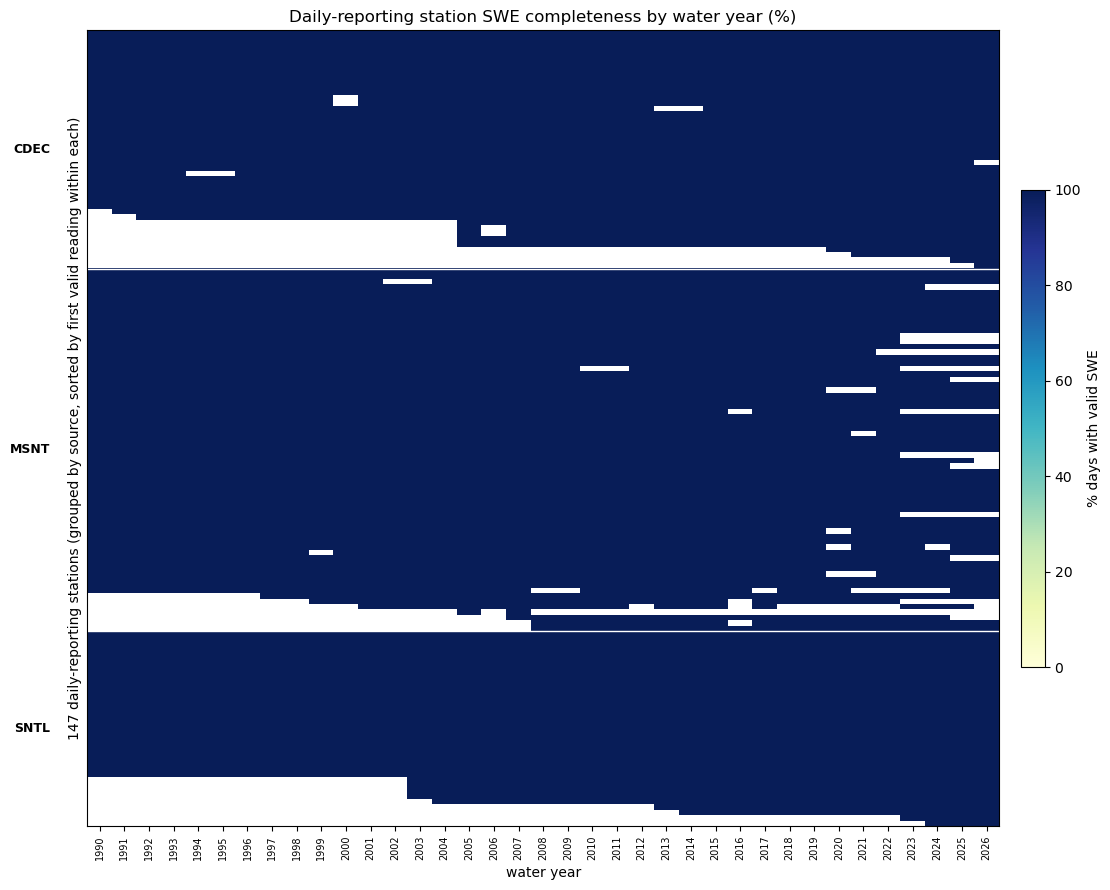

In [7]:
# per-station completeness heatmap, restricted to the 147 daily-reporting stations
# that actually feed CA_snowmelt_events_detrend_5day.ipynb's pipeline -- the other
# 165 manual-only stations are metadata-only there, so plotting their completeness
# here would be beside the point. Station names are too numerous to label
# individually; grouped by source and sorted by first valid date within each group,
# with source boundaries marked instead.
daily_swe = swe[swe.stationTriplet.isin(daily_ids)].copy()
daily_swe['water_year'] = daily_swe['date'].dt.year + (daily_swe['date'].dt.month >= 10).astype(int)

span = daily_swe.dropna(subset=['swe_mm']).groupby('stationTriplet')['date'].agg(first_valid='min')
order = (
    stations[stations.daily][['stationTriplet', 'source']]
    .merge(span, on='stationTriplet')
    .sort_values(['source', 'first_valid'])
)

completeness = (
    daily_swe.assign(has_val=daily_swe['swe_mm'].notna())
             .groupby(['stationTriplet', 'water_year'])['has_val']
             .mean()
             .mul(100)
             .unstack('water_year')
             .reindex(order['stationTriplet'])
)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(completeness, aspect='auto', cmap='YlGnBu', vmin=0, vmax=100)
ax.set_xticks(range(len(completeness.columns)))
ax.set_xticklabels(completeness.columns.astype(int), rotation=90, fontsize=7)
ax.set_yticks([])
ax.set_ylabel(f'{len(completeness)} daily-reporting stations (grouped by source, '
              f'sorted by first valid reading within each)')
ax.set_xlabel('water year')
ax.set_title('Daily-reporting station SWE completeness by water year (%)')

src_vals = order['source'].values
boundaries = np.flatnonzero(src_vals[1:] != src_vals[:-1]) + 0.5
for b in boundaries:
    ax.axhline(b, color='white', linewidth=1)
for s in source_order:
    rows = np.flatnonzero(src_vals == s)
    if len(rows):
        ax.text(-2, rows.mean(), s, ha='right', va='center', fontsize=9,
                fontweight='bold', clip_on=False)

cbar = plt.colorbar(im, ax=ax, orientation='vertical', shrink=0.6, pad=0.02)
cbar.set_label('% days with valid SWE')
plt.tight_layout()
plt.show()


## Summary

This combined network -- SNTL covering the Tahoe/Carson/Walker corridor north of
~38.1N, MSNT and CDEC filling the Yosemite/Mammoth/Kings Canyon/Sequoia/Kern terrain
south of it -- is exactly what `CA_snowmelt_events_detrend_5day.ipynb` analyzes: 312
stations total (36 SNTL, 67 MSNT, 209 CDEC), of which 147 report at daily resolution
and feed the event-detection pipeline (36 SNTL + 67 MSNT + 44 CDEC-D), the remaining
165 CDEC manual snow-course ("M"-only) sites metadata-only. See that notebook's
Section 1 for the exact loading/filtering logic reproduced here, and `proj_note.ipynb`
for how this combined network came together (CDEC added first to cover the gap south
of SNOTEL's footprint, MSNT added later as the better-provenance, AWDB-QC'd version
of the same stations where the two overlap).